# Per-maze Pipeline

Pools every usable mouse in a paradigm into one BC-VAE encoder → Transformer alignment decoder → conformal layer, and writes a bundle to `analyses/artifacts/<Paradigm>/ALL_MICE/seed_<SEED>/`. The compute lives in `src/`. Each cell is thin orchestration + figures. Driven per-maze by `analyses/run_mazes.py` (`make maze`), or run interactively by setting `TARGET_PARADIGM` in the parameters cell.

0. Setup: Papermill Parameters And Imports
1. Data: Discovery, Assembly, And Chronological Split
   - 1.1 Class Imbalance
2. Step 1: BC-VAE Encoder
3. Step 2: Transformer Alignment Decoder
4. Per-window Uncertainty Signals
5. Conformal Layer: Learned Scale + Class-conditional q_hat
   - 5.1 Training The Learned Scale
   - 5.2 Test Evaluation At The Deployed Operating Point
   - 5.3 The Achievable Frontier
6. Save The Bundle

## 0. Setup: Papermill Parameters And Imports

Papermill run parameters: cohort selection, epoch counts, hardware, data split, and the conformal target. `run_mazes.py` overrides only a few of these per maze.

In [ ]:
# papermill parameters: run parameters lives in this cell (run_mazes.py overrides only a few)

# cohort selection
# Pools every usable mouse in TARGET_PARADIGM into one encoder + decoder + conformal layer.
# TARGET_PARADIGM accepts a single paradigm ("More_Water", "Y_Maze", "Nested_All").
# Set TARGET_MICE to a list of ids to restrict the number of used mice. None = every usable mouse.
TARGET_MICE = None
# mice to hold out of the pool by id (a known-bad animal)
EXCLUDE_MICE = []
# specific sessions to discard before anything is loaded.
# Set per maze in run_mazes.py.
EXCLUDE_SESSIONS = []
# label used in figure titles and the artifact directory name
COHORT_LABEL = "ALL_MICE"
# the maze every mouse is locked to.
TARGET_PARADIGM = "More_Water"
# where the bundle is written, "" derives analyses/artifacts/<Paradigm>/ALL_MICE/seed_<SEED>/.
ARTIFACT_DIR = ""
# BC-VAE epochs (production 200, run_mazes.py --quick drops this to 2)
STEP1_EPOCHS = 200
# alignment-decoder epochs
STEP2_EPOCHS = 200

# data split
# one standard split, per session, over task (W) windows, chronological, used by everything:
#   train -> fit Step 1, Step 2, and the conformal MLP
#   val   -> early-stopping for all three, and the conformal quantile q_hat
#   test  -> evaluation, no stage has ever seen it
TRAIN_FRAC = 0.80
VAL_FRAC = 0.10
TEST_FRAC = 0.10

# shared training
# early-stop patience for the encoding-decoding pipeline
EARLY_STOP_PATIENCE = 20
# seed for every trained stage (torch, numpy, the conformal MLP). run_mazes.py sweeps it.
SEED = 42

# conformal layer
# miscoverage, the coverage target is 1 - $\alpha$.
ALPHA = 0.10
# learned-scale MLP training length, and its early-stop patience
MLP_EPOCHS = 300
MLP_EARLY_STOP_PATIENCE = 30

In [2]:
# Parameters
TARGET_PARADIGM = "More_Water"
EXCLUDE_SESSIONS = [
    "M46_250512",
    "M46_250424",
    "M25_241004",
    "M27_240920",
    "M19_241023",
    "M19_240922",
    "M21_241018",
    "M19_241018",
    "M21_241005",
]

Imports every `src/` function the notebook calls, fixes the reproducibility seed, and asserts the split fractions sum to one.

In [3]:
# Setup: imports, seeds, device, and the chronological-split constants.
# Pooled per-maze pipeline: the heavy lifting lives in src/ (imported below) and each cell is
# thin orchestration + figures.
import json
import sys
import time
from collections import Counter
from pathlib import Path

# run from the repo root so `from src.X import ...` resolves whichever directory
_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists()),
    Path.cwd(),
)
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from src.conformal.evaluate import (
    build_offsets,
    class_conditional_q_scaled,
    pool_indices,
    retrain_coverage_sweep,
)

# conformal: learned scale + per-region q_hat, and its evaluation
from src.conformal.learned import scale_of, train_scale
from src.conformal.predict import (
    class_conditional_prediction_sets,
    coverage_by_class,
    size_by_class,
)
from src.conformal.signals import (
    SIGNALS,
    SignalStats,
    compute_window_signals,
    standardize_signals,
)

# recording geometry + session eligibility (shared across the package)
from src.data.config import MIN_NEURONS_PER_SESSION, WINDOW_SIZE
from src.data.datasets import (
    HybridClassificationDataset,
    LatentSequenceDataset,
    hybrid_collate_fn,
)
from src.data.hybrid_io import build_hybrid_neuron_mapping

# data: discovery, assembly, windowing, and the chronological split
from src.db.client import get_database

# models: Step 1 (BC-VAE encoder), Step 2 (Transformer alignment decoder), decoder read
from src.models.alignment import AlignmentDecoder
from src.models.config import (
    BATCH_SIZE,
    KL_WARMUP_EPOCHS,
    LATENT_DIM,
    STEP1_LEARNING_RATE,
    STEP2_LEARNING_RATE,
    STEP2_SEQ_LEN,
)
from src.models.encoder import SharedTemporalClassifier
from src.models.latents import (
    extract_aligned_latents,
    extract_latents_hybrid,
    extract_logvar,
)
from src.models.metrics import decoder_report
from src.models.training import train_step1, train_step2
from src.utils.artifacts import build_arrays_bundle, jsonify, paradigm_slug
from src.utils.cohort import apply_session_exclusions, discover_cohort
from src.utils.pipeline_prep import (
    apply_window_region_labels,
    assemble_session_data,
    assert_chronological_disjoint,
    compute_class_counts,
    compute_y_boundaries,
    force_session_specific,
    gate_sessions_conformal,
    normalize_session_windows,
)

# parameters configurations
from src.utils.production_config import (
    DROP_STRADDLE_WINDOWS,
    LABEL_REDUCE,
    MLP_CAL_SPLIT,
    MLP_DEPTH,
    MLP_HIDDEN,
    MLP_KAPPA,
    MLP_SIZE_WEIGHT,
    MLP_TAU,
    STEP1_CLASS_WEIGHT_POWER,
    STEP1_KL_FREE_BITS,
    STEP1_KL_WEIGHT,
    STEP1_REGION_WEIGHT,
    STEP1_WEIGHT_DECAY,
    STEP2_CLASS_WEIGHT_POWER,
    STEP2_CONTRASTIVE_WEIGHT,
    STEP2_DROPOUT,
)

# data split: a genuine 3-way chronological train/val/test over task windows only.
FRACS = dict(train_frac=TRAIN_FRAC, val_frac=VAL_FRAC, test_frac=TEST_FRAC)
assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-9, (
    "train+val+test must sum to 1"
)

# `val` supplies q_hat, and the conformal quantile needs
# ceil((n+1)(1-ALPHA)) <= n on it.
MIN_VAL_WINDOWS = 50
MIN_TEST_WINDOWS = 20
_hard_floor = int(np.ceil(1 / ALPHA)) - 1
assert _hard_floor < MIN_VAL_WINDOWS, (
    f"MIN_VAL_WINDOWS must exceed {_hard_floor} at alpha={ALPHA}"
)

# reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

print(f"PyTorch {torch.__version__}  |  device {DEVICE}  |  seed {SEED}")
print(f"cohort   {COHORT_LABEL} | paradigm {TARGET_PARADIGM!r}")
print(
    f"split    chronological_task  ->  "
    f"train {TRAIN_FRAC:.0%} / val {VAL_FRAC:.0%} / test {TEST_FRAC:.0%}"
)
print(f"conformal target coverage {1 - ALPHA:.0%}  (alpha = {ALPHA})")
print(
    f"window   {WINDOW_SIZE} bins  |  latent dim {LATENT_DIM}  |  step-2 seq len {STEP2_SEQ_LEN}"
)

PyTorch 2.12.0+cu130  |  device cpu  |  seed 42
cohort   ALL_MICE | paradigm 'More_Water'
split    chronological_task  ->  train 80% / val 10% / test 10%
conformal target coverage 90%  (alpha = 0.1)
window   10 bins  |  latent dim 16  |  step-2 seq len 5


## 1. Data: Discovery, Assembly, And Chronological Split

Discovers every usable mouse and session in `TARGET_PARADIGM` and pools them into one cohort.

In [4]:
# Cohort: every usable mouse in TARGET_PARADIGM, pooled into one group. A mouse
# with < 2 valid sessions in the paradigm is skipped.
db = get_database()
print(f"Connected: {db.name}\n")
cohort = discover_cohort(
    db,
    TARGET_PARADIGM,
    target_mice=TARGET_MICE,
    exclude_mice=EXCLUDE_MICE,
)
_PARADIGMS = cohort.paradigms
paradigm = cohort.label
n_classes = cohort.n_classes
group = cohort.group
_pool_pre_exclusion = set(group)
group = apply_session_exclusions(group, EXCLUDE_SESSIONS, log_fn=print)

# provenance for metrics.json so the manual curation is auditable from the saved bundle alone.
EXCLUDED_REQUESTED = list(EXCLUDE_SESSIONS)
EXCLUDED_APPLIED = sorted(_pool_pre_exclusion - set(group))
session_to_mouse = cohort.session_to_mouse
session_to_paradigm = cohort.session_to_paradigm
cohort_mice = cohort.cohort_mice
mouse_id_used = COHORT_LABEL

print(f"cohort {COHORT_LABEL}  paradigm={paradigm!r}  ({n_classes} regions)")
if len(_PARADIGMS) > 1:
    print(f"  pooled over {len(_PARADIGMS)} paradigm blocks: {_PARADIGMS}")
print(f"  {len(cohort_mice)} usable mice: {cohort_mice}")
print(f"  {len(group)} candidate sessions pooled across mice")
if cohort.skipped:
    print(
        f"  {len(cohort.skipped)} mice skipped (no >=2 valid sessions in {TARGET_PARADIGM!r}): "
        f"{[f'M{m}: {w}' for m, w in cohort.skipped]}"
    )

Connected: functional_atlas



  EXCLUDE_SESSIONS: dropped 9 session(s) before assembly: ['M19_240922', 'M19_241018', 'M19_241023', 'M21_241005', 'M21_241018', 'M25_241004', 'M27_240920', 'M46_250424', 'M46_250512']
cohort ALL_MICE  paradigm='More_Water'  (8 regions)
  13 usable mice: [19, 21, 23, 25, 27, 40, 41, 46, 47, 48, 49, 50, 52]
  137 candidate sessions pooled across mice


Bins spikes into windows, labels each window's maze region, and splits every session chronologically into train/val/test.

In [5]:
# Assemble: bin spikes -> window -> region labels -> the chronological within-session split
y_boundaries = None
if paradigm == "More_Water":
    _, _prelim = build_hybrid_neuron_mapping(db, group)
    y_boundaries = compute_y_boundaries(db, group, _prelim)

# The split. Fractions passed explicitly.
print(
    f"\nAssembling: bin spikes -> window -> region labels -> chronological_task split {FRACS}"
)
session_data, valid_sessions, session_configs, _, n_shared = assemble_session_data(
    db, group, paradigm, y_boundaries=y_boundaries, **FRACS
)

if n_shared > 0:
    print(
        f"forcing session-specific decoding: dropping {n_shared} pooled 'shared' neurons"
    )
    force_session_specific(session_configs)
    n_shared = 0

# honest window labels: modal region over the window
apply_window_region_labels(
    session_data,
    valid_sessions,
    paradigm,
    y_boundaries=y_boundaries,
    reduce=LABEL_REDUCE,
    drop_straddle=DROP_STRADDLE_WINDOWS,
    log_fn=print,
)

# assemble_session_data silently drops sessions that fail.
_unused = [s for s in group if s not in valid_sessions]
if _unused:
    print(
        f"\n{len(_unused)}/{len(group)} candidate session(s) rejected by assemble_session_data "
        f"(< {MIN_NEURONS_PER_SESSION} neurons, too few task windows, or < 2 regions):"
    )
    print("    " + ", ".join(_unused))

# split-aware session gate: each session must support q_hat on its own val + a test block
_dropped = gate_sessions_conformal(
    session_data, valid_sessions, MIN_VAL_WINDOWS, MIN_TEST_WINDOWS
)
if _dropped:
    print(
        f"\ndropped {len(_dropped)} session(s) - val/test block too small to support "
        f"a {1 - ALPHA:.0%} quantile:"
    )
    for s, nv, nt in _dropped:
        why = ([f"val={nv}<{MIN_VAL_WINDOWS}"] if nv < MIN_VAL_WINDOWS else []) + (
            [f"test={nt}<{MIN_TEST_WINDOWS}"] if nt < MIN_TEST_WINDOWS else []
        )
        print(f"    {s}: {', '.join(why)}")
if not valid_sessions:
    raise RuntimeError(
        f"M{mouse_id_used}/{paradigm}: no session survives the split gate "
        f"(val >= {MIN_VAL_WINDOWS}, test >= {MIN_TEST_WINDOWS}). Mouse is ineligible."
    )

# the blocks must be time-ordered.
assert_chronological_disjoint(session_data, valid_sessions)


Assembling: bin spikes -> window -> region labels -> chronological_task split {'train_frac': 0.8, 'val_frac': 0.1, 'test_frac': 0.1}



38/137 candidate session(s) rejected by assemble_session_data (< 5 neurons, too few task windows, or < 2 regions):
    M19_240914, M19_241005, M27_241004, M40_250126, M40_250207, M40_250223, M40_250303, M40_250321, M40_250323, M46_250330, M46_250414, M46_250418, M46_250420, M46_250430, M47_250215, M47_250223, M47_250301, M47_250303, M47_250307, M47_250309, M48_250214, M48_250222, M48_250224, M48_250228, M48_250302, M48_250317, M48_250322, M48_250420, M48_250424, M48_250426, M48_250504, M49_250419, M49_250425, M49_250509, M49_250512, M50_250411, M50_250413, M50_250419

dropped 4 session(s) - val/test block too small to support a 90% quantile:
    M25_241016: val=46<50
    M50_250428: val=7<50, test=5<20
    M50_250501: val=12<50, test=10<20
    M50_250516: val=40<50


Prints the realized per-session and per-mouse split composition, then z-scores each neuron on train-only statistics.

In [6]:
# realized split per session + per-mouse composition of the dataset
print(f"{'session':<24} {'train':>6} {'val':>5} {'test':>5} | realized split")
for s in valid_sessions:
    d = session_data[s]
    tr, va, te = (np.sort(d[k]) for k in ("train_idx", "val_idx", "test_idx"))
    n = len(tr) + len(va) + len(te)
    print(
        f"{s:<24} {len(tr):>6} {len(va):>5} {len(te):>5} | "
        f"{len(tr) / n:.0%}/{len(va) / n:.0%}/{len(te) / n:.0%}"
    )
_tot = {
    k: sum(len(session_data[s][f"{k}_idx"]) for s in valid_sessions)
    for k in ("train", "val", "test")
}
_N = sum(_tot.values())
print(
    f"{'pooled':<24} {_tot['train']:>6} {_tot['val']:>5} {_tot['test']:>5} | "
    f"{_tot['train'] / _N:.0%}/{_tot['val'] / _N:.0%}/{_tot['test'] / _N:.0%}"
    f"   <- target {TRAIN_FRAC:.0%}/{VAL_FRAC:.0%}/{TEST_FRAC:.0%}"
)

_mouse_sessions = Counter(session_to_mouse[s] for s in valid_sessions)
_mouse_windows = Counter()
for s in valid_sessions:
    _mouse_windows[session_to_mouse[s]] += len(session_data[s]["regions"])
_cohort_final = sorted(_mouse_sessions)
print(
    f"\npooled cohort after all gates: {len(valid_sessions)} sessions from "
    f"{len(_cohort_final)} mice"
)
print(f"  {'mouse':>7} {'sessions':>9} {'windows':>9}")
for _m in _cohort_final:
    print(f"  {'M' + str(_m):>7} {_mouse_sessions[_m]:>9} {_mouse_windows[_m]:>9}")
_lost = [m for m in cohort_mice if m not in set(_cohort_final)]
if _lost:
    print(f"  mice that lost ALL sessions to the split gate: {_lost}")

# z-score each neuron using train statistics only (no leakage from val/test)
normalize_session_windows(session_data, valid_sessions)
class_counts = compute_class_counts(session_data, valid_sessions)
print(f"\n{len(valid_sessions)} usable sessions")
print(f"class counts across the {n_classes} regions: {class_counts}")

session                   train   val  test | realised split
M19_240918                 1885   236   235 | 80%/10%/10%
M19_240925                 1432   181   170 | 80%/10%/10%
M19_241011                 1380   170   172 | 80%/10%/10%
M19_241102                 1444   174   176 | 80%/10%/10%
M19_241104                 1947   239   226 | 81%/10%/9%
M21_240918                 1718   218   210 | 80%/10%/10%
M21_240922                 1626   200   197 | 80%/10%/10%
M21_240925                 1952   241   243 | 80%/10%/10%
M21_241011                 1731   216   213 | 80%/10%/10%
M21_241023                 1588   196   192 | 80%/10%/10%
M21_241030                 1506   191   191 | 80%/10%/10%
M21_241103                 1815   214   223 | 81%/10%/10%
M23_240914                 1506   188   186 | 80%/10%/10%
M23_240918                 1304   150   143 | 82%/9%/9%
M23_240922                 1124   125   116 | 82%/9%/8%
M25_240916                  998   119   116 | 81%/10%/9%
M25_240923       


95 usable sessions
class counts across the 8 regions: {0: 89798, 1: 24967, 2: 14910, 3: 7057, 4: 4198, 5: 2709, 6: 1130, 7: 2783}


### 1.1 Class Imbalance: Why Balanced Accuracy and Per-region Coverage

Global region-occupancy distribution across the pooled cohort, against the chance and majority-class baselines.

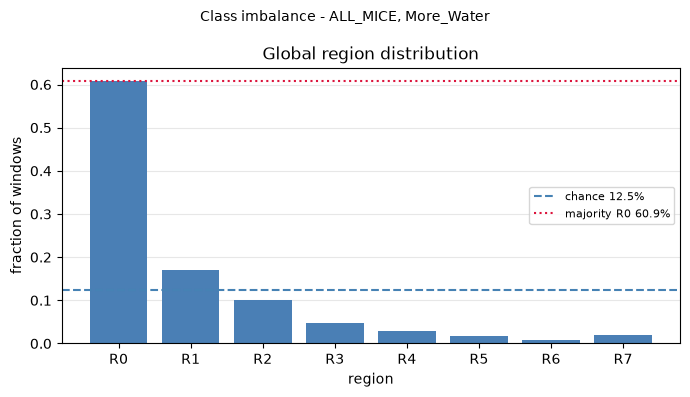

In [7]:
_tot = np.array([class_counts.get(r, 0) for r in range(n_classes)], float)
_glob = _tot / _tot.sum()
_maj = int(_glob.argmax())

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(n_classes), _glob, color="#4a7fb5", zorder=2)
ax.axhline(
    1 / n_classes,
    ls="--",
    color="steelblue",
    lw=1.5,
    label=f"chance {1 / n_classes:.1%}",
)
ax.axhline(
    _glob.max(),
    ls=":",
    color="crimson",
    lw=1.5,
    label=f"majority R{_maj} {_glob.max():.1%}",
)
ax.set_xticks(range(n_classes))
ax.set_xticklabels([f"R{r}" for r in range(n_classes)])
ax.set_xlabel("region")
ax.set_ylabel("fraction of windows")
ax.set_title("Global region distribution")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3, zorder=1)
fig.suptitle(
    f"Class imbalance - {mouse_id_used}, {paradigm}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

## 2. Step 1: BC-VAE Encoder

Builds the BC-VAE encoder and trains it on the train split, early-stopping on val.

In [8]:
# Step 1: encoder, dataloaders, training
step1_model = SharedTemporalClassifier(
    n_shared=n_shared, session_configs=session_configs, n_classes=n_classes
).to(DEVICE)
print(
    f"{type(step1_model).__name__}: {sum(p.numel() for p in step1_model.parameters()):,} params "
    f"| {len(valid_sessions)} sessions | n_shared={n_shared} | {n_classes} regions"
)

# train on `train_idx` only, `val_idx` is used for early stopping
BATCH = min(BATCH_SIZE, 256)
train_ds = HybridClassificationDataset(
    {s: session_data[s] for s in valid_sessions},
    index_key="train_idx",
)
val_ds = HybridClassificationDataset(
    {s: session_data[s] for s in valid_sessions},
    index_key="val_idx",
)
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH,
    shuffle=True,
    collate_fn=hybrid_collate_fn,
    drop_last=False,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH,
    shuffle=False,
    collate_fn=hybrid_collate_fn,
    drop_last=False,
)
print(
    f"train {len(train_ds)} windows ({len(train_loader)} batches batch_size={BATCH})  |  "
    f"val {len(val_ds)} windows (early stopping only)"
)

print(
    f"Step 1  |  {STEP1_EPOCHS} epochs, lr={STEP1_LEARNING_RATE}, "
    f"head wd={STEP1_WEIGHT_DECAY}, patience={EARLY_STOP_PATIENCE}"
)
print(
    f"  loss = Poisson NLL(raw counts)  +  {STEP1_KL_WEIGHT} * KL  +  "
    f"{STEP1_REGION_WEIGHT} * CE(region, class-weighted^{STEP1_CLASS_WEIGHT_POWER})"
)

step1_model, step1_hist = train_step1(
    model=step1_model,
    loader=train_loader,
    val_loader=val_loader,
    device=DEVICE,
    log_fn=print,
    n_classes=n_classes,
    num_epochs=STEP1_EPOCHS,
    lr=STEP1_LEARNING_RATE,
    classifier_weight_decay=STEP1_WEIGHT_DECAY,
    region_weight=STEP1_REGION_WEIGHT,
    class_weight_power=STEP1_CLASS_WEIGHT_POWER,
    class_counts=class_counts,
    kl_weight=STEP1_KL_WEIGHT,
    kl_free_bits=STEP1_KL_FREE_BITS,
    early_stop_patience=EARLY_STOP_PATIENCE,
    log_every=max(1, STEP1_EPOCHS // 20),
)

/home/guilherme/imperial/IRP/IRP-Repo/irp-ggf25/.venv/lib/python3.12/site-packages/torch/nn/modules/linear.py:124: UserWarning: Initializing zero-element tensors is a no-op
  init.kaiming_uniform_(self.weight, a=math.sqrt(5))


SharedTemporalClassifier: 876,577 params | 95 sessions | n_shared=0 | 8 regions


train 147552 windows (577 batches batch_size=256)  |  val 18284 windows (early stopping only)
Step 1  |  200 epochs, lr=0.001, head wd=0.01, patience=20
  loss = Poisson NLL(raw counts)  +  0.5 * KL  +  0.2 * CE(region, class-weighted^1.0)


    Class weights (power=1.0): ['0.04', '0.15', '0.25', '0.54', '0.90', '1.40', '3.35', '1.36']
    Training Step 1 (Recon + Region + KL, NO contrastive)...


  [Step1] Epoch   10/200  loss=-1.6023  recon=-2.2249  region=1.4493  kl=0.6654 (w=0.500)  acc=38.6%  val=-1.4283


  [Step1] Epoch   20/200  loss=-1.6855  recon=-2.2862  region=1.3067  kl=0.6786 (w=0.500)  acc=39.7%  val=-1.4551


      [Step1] early stop @ epoch 24/200
      [Step1] restored best-val weights (val_loss=-1.5371)


Step-1 convergence read: the total-loss curve.

epochs run       : 24 / 200  (early-stopped, best-val weights restored)
recon (Poisson)  : -1.373 -> -2.300
KL               : 0.689  (weight 0.50)
region CE  train : 1.252
region CE  val   : 1.915


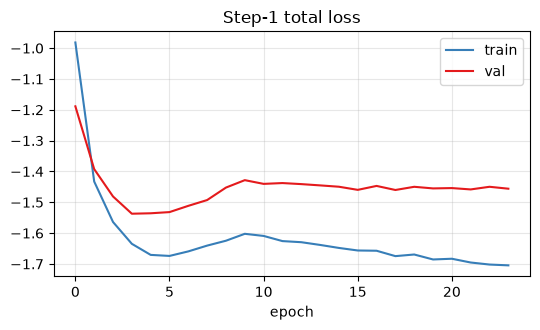

In [9]:
# Step-1 convergence read
_h = step1_hist
_val_region = [v for v in _h.get("val_region", []) if v is not None]
print(
    f"epochs run       : {len(_h['loss'])} / {STEP1_EPOCHS}"
    + ("  (early-stopped)" if len(_h["loss"]) < STEP1_EPOCHS else "")
)
print(
    f"restored epoch   : {_h['best_epoch']}  "
    f"(early stopping starts after the {KL_WARMUP_EPOCHS}-epoch KL warm-up)"
)
print(f"recon (Poisson)  : {_h['recon'][0]:.3f} -> {_h['recon'][-1]:.3f}")
print(f"KL               : {_h['kl'][-1]:.3f}  (weight {_h['kl_weight'][-1]:.2f})")
print(f"region CE  train : {_h['region'][-1]:.3f}")
if _val_region:
    _vr = _val_region[-1]
    print(f"region CE  val   : {_vr:.3f}")
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.plot(_h["loss"], label="train", color="#377eb8")
if any(v is not None for v in _h.get("val_loss", [])):
    ax.plot(
        [v if v is not None else np.nan for v in _h["val_loss"]],
        label="val",
        color="#e41a1c",
    )
ax.axvspan(0, KL_WARMUP_EPOCHS - 1, color="0.85", label="KL warm-up")
if _h["best_epoch"] is not None:
    ax.axvline(_h["best_epoch"] - 1, ls="--", color="k", lw=1, label="restored")
ax.set_title("Step-1 total loss")
ax.set_xlabel("epoch")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Extracts each window's BC-VAE latent (mu) and posterior log-variance (logvar) from the trained Step-1 encoder.

In [10]:
# Step 1: extract latents (mu) and the posterior log-variance (logvar)
for s in valid_sessions:
    session_data[s]["step1_all_latents"] = extract_latents_hybrid(
        step1_model, session_data[s]["windows"], s, DEVICE
    )
    session_data[s]["logvar"] = extract_logvar(
        step1_model, session_data[s]["windows"], s, DEVICE
    )

_lat = np.concatenate([session_data[s]["step1_all_latents"] for s in valid_sessions])
_lv = np.concatenate([session_data[s]["logvar"] for s in valid_sessions])
print(f"latents  {_lat.shape}   logvar {_lv.shape}")

latents  (234636, 16)   logvar (234636, 16)


## 3. Step 2: Transformer Alignment Decoder

Builds the Transformer alignment decoder and trains it (Step 2) on the frozen Step-1 latents.

In [11]:
# Step 2: decoder, sequence loaders, training
alignment_decoder = AlignmentDecoder(
    latent_dim=LATENT_DIM,
    n_classes=n_classes,
    seq_len=STEP2_SEQ_LEN,
    dropout=STEP2_DROPOUT,
).to(DEVICE)
print(
    f"AlignmentDecoder: {sum(p.numel() for p in alignment_decoder.parameters()):,} params "
    f"| seq_len={STEP2_SEQ_LEN} x latent {LATENT_DIM} -> {n_classes} regions"
)

# same blocks as Step 1: fit on `train`, early-stop on `val`, never touch cal/test
train_seq_ds = LatentSequenceDataset(
    session_data,
    valid_sessions,
    seq_len=STEP2_SEQ_LEN,
    index_key="train_idx",
)
val_seq_ds = LatentSequenceDataset(
    session_data,
    valid_sessions,
    seq_len=STEP2_SEQ_LEN,
    index_key="val_idx",
)
train_seq_loader = DataLoader(train_seq_ds, batch_size=BATCH, shuffle=True)
val_seq_loader = DataLoader(val_seq_ds, batch_size=BATCH, shuffle=False)
print(
    f"train {len(train_seq_ds)} sequences  |  val {len(val_seq_ds)} sequences (early stopping)"
)

print(
    f"Step 2  |  {STEP2_EPOCHS} epochs, lr={STEP2_LEARNING_RATE}, "
    f"patience={EARLY_STOP_PATIENCE}, encoder frozen"
)
print(
    f"  loss = CE(region, class-weighted^{STEP2_CLASS_WEIGHT_POWER})  +  "
    f"{STEP2_CONTRASTIVE_WEIGHT} * NT-Xent"
)

alignment_decoder, step2_hist = train_step2(
    alignment_decoder=alignment_decoder,
    loader=train_seq_loader,
    val_loader=val_seq_loader,
    device=DEVICE,
    log_fn=print,
    n_classes=n_classes,
    num_epochs=STEP2_EPOCHS,
    lr=STEP2_LEARNING_RATE,
    class_counts=class_counts,
    class_weight_power=STEP2_CLASS_WEIGHT_POWER,
    contrastive_weight=STEP2_CONTRASTIVE_WEIGHT,
    early_stop_patience=EARLY_STOP_PATIENCE,
    log_every=max(1, STEP2_EPOCHS // 20),
)

AlignmentDecoder: 119,128 params | seq_len=5 x latent 16 -> 8 regions


train 147552 sequences  |  val 18284 sequences (early stopping)
Step 2  |  200 epochs, lr=0.0003, patience=20, encoder frozen
  loss = CE(region, class-weighted^1.0)  +  2.0 * NT-Xent
    Class weights (power=1.0): ['0.04', '0.15', '0.25', '0.54', '0.90', '1.40', '3.35', '1.36']
    Training Step 2 (Contrastive + Classification on frozen latents)...


  [Step2] Epoch   10/200  loss=11.6600  region=1.1752  contrastive=5.2424  acc=51.5%  val=12.4059 (r=1.6684 c=5.3687)


  [Step2] Epoch   20/200  loss=11.4799  region=1.0539  contrastive=5.2130  acc=52.9%  val=12.5684 (r=1.8499 c=5.3593)


      [Step2] early stop @ epoch 23/200
      [Step2] restored best-val weights (val_metric=1.5162)


Step-2 convergence read: the total-loss curve for the alignment decoder.

epochs run     : 23 / 200  (early-stopped, best-val weights restored)
region CE      : train 1.023   val 1.849
contrastive    : 5.204
train accuracy : 53.5%


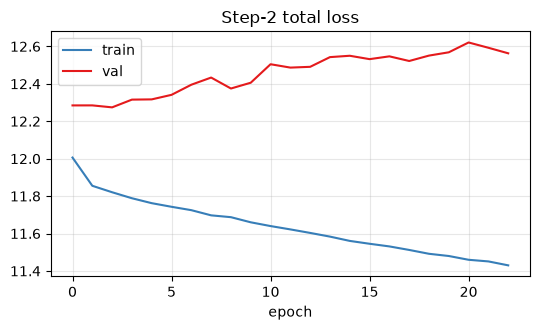

In [12]:
# Step 2: convergence read + curves
_h2 = step2_hist
_vr2 = [v for v in _h2.get("val_region", []) if v is not None]
print(
    f"epochs run     : {len(_h2['loss'])} / {STEP2_EPOCHS}"
    + (
        "  (early-stopped, best-val weights restored)"
        if len(_h2["loss"]) < STEP2_EPOCHS
        else ""
    )
)
print(
    f"region CE      : train {_h2['region'][-1]:.3f}"
    + (f"   val {_vr2[-1]:.3f}" if _vr2 else "")
)
print(f"contrastive    : {_h2['contrastive'][-1]:.3f}")
print(f"train accuracy : {_h2['acc'][-1]:.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.plot(_h2["loss"], label="train", color="#377eb8")
if any(v is not None for v in _h2.get("val_loss", [])):
    ax.plot(
        [v if v is not None else np.nan for v in _h2["val_loss"]],
        label="val",
        color="#e41a1c",
    )
ax.set_title("Step-2 total loss")
ax.set_xlabel("epoch")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Runs the trained decoder on every window to get softmax probabilities, pools every window across sessions into the arrays the rest of the notebook indexes into, and reports raw accuracy on the held-out test block.

In [ ]:
# Step 2: softmax probabilities, and decoder results
alignment_decoder.eval()
with torch.no_grad():
    for s in valid_sessions:
        aligned = extract_aligned_latents(
            alignment_decoder,
            session_data[s]["step1_all_latents"],
            DEVICE,
            STEP2_SEQ_LEN,
        )
        logits = alignment_decoder.decoder(torch.from_numpy(aligned).to(DEVICE))
        session_data[s]["probs"] = torch.softmax(logits, dim=-1).cpu().numpy()

# Pool every window across sessions, in valid_sessions order, once. Everything after this
# cell indexes these arrays with the pooled split indices.
_off = build_offsets(session_data, valid_sessions)
P_all = np.concatenate([session_data[s]["probs"] for s in valid_sessions]).astype(
    np.float64
)
y_all = np.concatenate([session_data[s]["regions"] for s in valid_sessions]).astype(int)
# session id per pooled window
G_all = np.concatenate(
    [
        np.full(len(session_data[s]["regions"]), si)
        for si, s in enumerate(valid_sessions)
    ]
)
fit_i = pool_indices(
    session_data, valid_sessions, "train_idx", _off
)  # sigma parameters
val_i = pool_indices(
    session_data, valid_sessions, "val_idx", _off
)  # early stop + q_hat
test_i = pool_indices(session_data, valid_sessions, "test_idx", _off)  # never seen
assert not (set(fit_i) & set(val_i)), "the sigma fitting block overlaps q_hat's block"
assert not (set(val_i) & set(test_i)), "q_hat and test blocks overlap"
y_te = y_all[test_i]

# decoder_report (src/models/metrics.py): the reported accuracy
_rep = decoder_report(y_te, P_all[test_i], n_classes)
_raw = _rep["raw_accuracy"]

print(
    f"Held-out test block: {len(y_te)} windows across {len(valid_sessions)} sessions\n"
)
print(f"Decoder accuracy   {_raw:>7.1%}")

## 4. Per-window Uncertainty Signals: (entropy, variance, and the two Jacobians)

Computes the four per-window uncertainty signals (entropy, variance, and the two Jacobians) the conformal layer is trained on.

In [14]:
# Per-window uncertainty signals: entropy, variance, and the two Jacobians
# compute_window_signals (src/conformal/signals.py) writes session_data[s]["signals"] as an
# (n, 4) matrix in signals order.
_t0 = time.time()
compute_window_signals(
    step1_model,
    alignment_decoder,
    session_data,
    valid_sessions,
    seq_len=STEP2_SEQ_LEN,
    device=DEVICE,
)
_elapsed = time.time() - _t0
_n_win = sum(len(session_data[s]["regions"]) for s in valid_sessions)
print(
    f"signals: {_n_win} windows x {len(SIGNALS)} = {_n_win * len(SIGNALS):,} values "
    f"in {_elapsed:.1f}s  ({1000 * _elapsed / _n_win:.2f} ms/window)"
)

signals: 234636 windows x 4 = 938,544 values in 1029.9s  (4.39 ms/window)


## 5. Conformal Layer: Learned Scale + Class-conditional q_hat

### 5.1 Training The Learned Scale

Trains the class-conditional learned-scale sigma(x) and calibrates per-region conformal quantiles from it.

In [ ]:
# Conformal layer: class-conditional learned scale
# The proposed layer: a shared sigma(x) trained under a per-region loss,
# calibrated with per-region quantiles, applied
# with a per-region threshold on the sigma-scaled score. Per-region objectives + shared parameters.
U_raw = np.concatenate([session_data[s]["signals"] for s in valid_sessions])
print(
    f"conformal:  fit sigma on train ({len(fit_i)})  ->  early-stop + per-region q_hat on "
    f"val ({len(val_i)})  ->  test ({len(test_i)})"
)

# standardize signals with statistics frozen on the fitting block (train)
_sigstats = SignalStats.fit(U_raw[fit_i])
Z = standardize_signals(U_raw, _sigstats)

# fit sigma under the class-conditional loss
_t0 = time.time()
scale_net, scale_report = train_scale(
    Z[fit_i],
    P_all[fit_i],
    y_all[fit_i],
    alpha=ALPHA,
    hidden=MLP_HIDDEN,
    depth=MLP_DEPTH,
    epochs=MLP_EPOCHS,
    tau=MLP_TAU,
    kappa=MLP_KAPPA,
    size_weight=MLP_SIZE_WEIGHT,
    val_signals_z=Z[val_i],
    val_probs=P_all[val_i],
    val_labels=y_all[val_i],
    early_stop_patience=MLP_EARLY_STOP_PATIENCE,
    seed=SEED,
    device=str(DEVICE),
    n_classes=n_classes,
    split=MLP_CAL_SPLIT,
    groups=G_all[fit_i],
    val_groups=G_all[val_i],
)
sigma = scale_of(scale_net, Z, device=str(DEVICE))
if scale_report.best_epoch is not None:
    print(
        f"early stopping: ran {scale_report.epochs} epochs, restored best at epoch "
        f"{scale_report.best_epoch}"
    )
print(
    f"MLP: {MLP_HIDDEN}x{MLP_DEPTH}, {MLP_EPOCHS} epochs in {time.time() - _t0:.1f}s   "
    f"sigma mean {sigma.mean():.3f} sd {sigma.std():.3f} "
    f"range [{sigma.min():.2f}, {sigma.max():.2f}]"
)
if scale_report.collapsed_to_standard:
    print(
        "  sigma did NOT move from 1: the signals earned nothing -> the learned scale "
        "collapsed to a flat sigma = 1."
    )

# per-region calibration for the learned scale
# q_hat_c from the scaled cal scores of region c
q_by_class = class_conditional_q_scaled(P_all, y_all, sigma, val_i, n_classes, ALPHA)

Diagnostic figure: the sigma-training loss curve, the learned-scale histogram, and the soft coverage/size trade the training loss balanced.

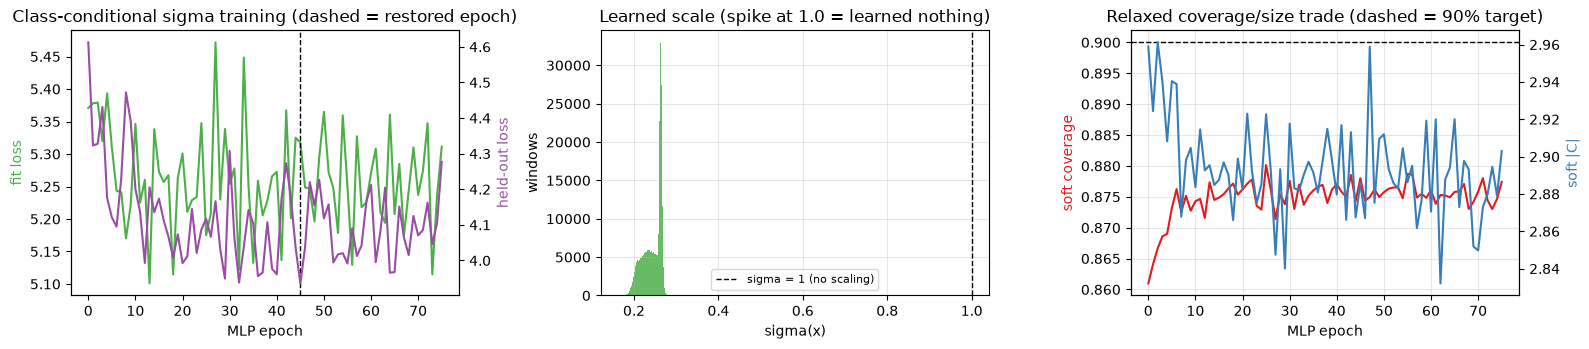

In [18]:
# figure: sigma training curve + sigma histogram
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
_axb = ax[0].twinx()
ax[0].plot(scale_report.loss, color="#4daf4a", label="fit loss")
if scale_report.earlystop_loss is not None:
    _axb.plot(scale_report.earlystop_loss, color="#984ea3", label="held-out loss")
    if scale_report.best_epoch is not None:
        ax[0].axvline(scale_report.best_epoch, ls="--", color="k", lw=1)
ax[0].set_xlabel("MLP epoch")
ax[0].set_ylabel("fit loss", color="#4daf4a")
_axb.set_ylabel("held-out loss", color="#984ea3")
ax[0].set_title("Class-conditional sigma training (dashed = restored epoch)")
ax[1].hist(sigma, bins=50, color="#4daf4a", alpha=0.85)
ax[1].axvline(1.0, ls="--", color="k", lw=1, label="sigma = 1 (no scaling)")
ax[1].set_xlabel("sigma(x)")
ax[1].set_ylabel("windows")
ax[1].set_title("Learned scale (spike at 1.0 = learned nothing)")
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)

# What the relaxed loss was actually trading, epoch by epoch.
_axc = ax[2].twinx()
ax[2].plot(scale_report.val_coverage, color="#e41a1c", label="soft coverage")
ax[2].axhline(1 - ALPHA, ls="--", color="k", lw=1)
_axc.plot(scale_report.val_size, color="#377eb8", label="soft |C|")
ax[2].set_xlabel("MLP epoch")
ax[2].set_ylabel("soft coverage", color="#e41a1c")
_axc.set_ylabel("soft |C|", color="#377eb8")
ax[2].set_title(f"Relaxed coverage/size trade (dashed = {1 - ALPHA:.0%} target)")
ax[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.2 Test Evaluation At The Deployed Operating Point

Builds the deployed prediction sets on the test block once, then reads off everything `metrics.json` stores about them: marginal coverage and set size, per-region coverage, and per-session coverage. Per-session values are saved for `cross_maze.ipynb` and only summarized here.

In [ ]:
# Test evaluation: the deployed sets on the test block, built once
sets_te = class_conditional_prediction_sets(P_all[test_i], sigma[test_i], q_by_class)
size_te = np.array([len(s) for s in sets_te], dtype=float)
cov_te = np.array([y in s for y, s in zip(y_te, sets_te, strict=True)], dtype=float)
err_te = (P_all[test_i].argmax(1) != y_te).astype(float)
sess_te = G_all[test_i]

conformal = {
    "alpha": ALPHA,
    "cal_split": MLP_CAL_SPLIT,
    "arms": {
        "learned-scale class-conditional": {
            "set_size": float(size_te.mean()),
            "q_hat_by_region": {
                int(c): (
                    None if not np.isfinite(q_by_class[c]) else float(q_by_class[c])
                )
                for c in range(n_classes)
            },
        }
    },
}
print(
    f"test: coverage {cov_te.mean():.3f} (target {1 - ALPHA:.0%})   "
    f"|C| {size_te.mean():.2f}   |C|/K {size_te.mean() / n_classes:.2f}"
)

# per region
cov_by_region = coverage_by_class(sets_te, y_te, n_classes=n_classes, min_count=5)
size_by_region = size_by_class(sets_te, y_te, n_classes=n_classes, min_count=5)
_cnt = np.bincount(y_te, minlength=n_classes)
print(f"\n  {'region':>7} {'n':>6} {'coverage':>9} {'|C|':>6}")
for r in range(n_classes):
    if _cnt[r] == 0:
        continue
    b, sz = cov_by_region.get(r, np.nan), size_by_region.get(r, np.nan)
    flag = "  <- under-covered" if np.isfinite(b) and b < 0.80 else ""
    print(f"  {'R' + str(r):>7} {_cnt[r]:>6} {b:>9.2f} {sz:>6.2f}{flag}")
_finite = [v for v in cov_by_region.values() if np.isfinite(v)]
if _finite:
    print(f"  worst region {min(_finite):.3f}")
conformal["per_region_coverage"] = {
    "learned": {
        int(k): (None if not np.isfinite(v) else float(v))
        for k, v in cov_by_region.items()
    },
    "n_test": {int(r): int(_cnt[r]) for r in range(n_classes)},
    "size": {
        int(k): (None if not np.isfinite(v) else float(v))
        for k, v in size_by_region.items()
    },
}

# per session: saved for cross_maze.ipynb (one point per session), only summarized here
_per_session = []
for si in np.unique(sess_te):
    m = sess_te == si
    _per_session.append(
        {
            "session": valid_sessions[int(si)],
            "n": int(m.sum()),
            "coverage": float(cov_te[m].mean()),
            "error": float(err_te[m].mean()),
            "meets_target": bool(cov_te[m].mean() >= 1 - ALPHA),
        }
    )
_sess_cov = np.array([r["coverage"] for r in _per_session])
_n_below = int((_sess_cov < 1 - ALPHA).sum())
print(
    f"\n  sessions below target: {_n_below}/{len(_per_session)}   per-session coverage "
    f"min {_sess_cov.min():.2f}, median {np.median(_sess_cov):.2f}"
)
conformal["test_coverage"] = {
    "whole_test": {
        "coverage": float(cov_te.mean()),
        "n": len(y_te),
        "error": float(err_te.mean()),
        "meets_target": bool(cov_te.mean() >= 1 - ALPHA),
    },
    "per_session": _per_session,
    "n_sessions_below_target": _n_below,
}

### 5.3 The Achievable Frontier

Retrains sigma at 20 target coverage levels, tracing the achievable coverage-sharpness frontier.

In [19]:
# Retrains sigma per target (achievable frontier) -> conformal["retrain_sweep"]
# Retrain sigma at each target (matched alpha), tracing the method's achievable frontier

# shared target grid: 20 points, 1%-99% (the widest safe range)
COV_TARGETS = np.round(np.linspace(0.01, 0.99, 20), 3)

_t0 = time.time()
try:
    conformal["retrain_sweep"] = {
        "learned": retrain_coverage_sweep(
            Z,
            P_all,
            y_all,
            fit_i,
            val_i,
            test_i,
            n_classes,
            COV_TARGETS,
            hidden=MLP_HIDDEN,
            depth=MLP_DEPTH,
            epochs=MLP_EPOCHS,
            tau=MLP_TAU,
            kappa=MLP_KAPPA,
            size_weight=MLP_SIZE_WEIGHT,
            early_stop_patience=MLP_EARLY_STOP_PATIENCE,
            seed=SEED,
            device=str(DEVICE),
            split=MLP_CAL_SPLIT,
            groups=G_all,
        ),
    }
    print(
        f"retrain sweep: {len(COV_TARGETS)} targets re-trained "
        f"in {time.time() - _t0:.1f}s"
    )
    print(f"  {'target':>7} {'achieved':>9} {'|C|/K':>6}")
    for r in conformal["retrain_sweep"]["learned"]:
        print(
            f"  {r['target']:>7.1%} {r['coverage']:>9.1%} {r['size'] / n_classes:>6.2f}"
        )
except Exception as _e:  # never let the validation curve cost the trained models
    conformal["retrain_sweep"] = None
    print(
        f"retrain sweep (Curve B) skipped after {time.time() - _t0:.1f}s: "
        f"{type(_e).__name__}: {_e}"
    )

retrain sweep: 20 targets re-trained in 1559.7s
   target  achieved  |C|/K
     1.0%      0.4%   0.00
     6.2%      3.9%   0.01
    11.3%      7.6%   0.02
    16.5%     11.6%   0.04
    21.6%     15.7%   0.05
    26.8%     19.8%   0.08
    31.9%     24.8%   0.10
    37.1%     29.7%   0.11
    42.3%     34.4%   0.13
    47.4%     39.2%   0.15
    52.6%     45.0%   0.18
    57.7%     51.1%   0.21
    62.9%     56.7%   0.24
    68.1%     62.3%   0.28
    73.2%     67.3%   0.31
    78.4%     72.6%   0.34
    83.5%     78.6%   0.39
    88.7%     84.5%   0.45
    93.8%     90.9%   0.57
    99.0%     98.1%   0.77


## 6. Save the bundle: models + metrics.json + arrays.npz

Saves the trained models, `metrics.json`, and `arrays.npz` to the paradigm's artifact directory. The bundle `cross_maze.ipynb` reads.

In [23]:
# Save the bundle: models + metrics.json + arrays.npz
ARTIFACT_DIR = (
    Path(ARTIFACT_DIR)
    if ARTIFACT_DIR
    else _ROOT
    / "analyses"
    / "artifacts"
    / paradigm_slug(paradigm)
    / COHORT_LABEL
    / f"seed_{SEED}"
)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print(f"saving -> {ARTIFACT_DIR}")

# 1. models
torch.save(
    {
        "state_dict": step1_model.state_dict(),
        "session_configs": session_configs,
        "n_classes": n_classes,
        "n_shared": n_shared,
    },
    ARTIFACT_DIR / "step1_encoder.pt",
)
torch.save(
    {
        "state_dict": alignment_decoder.state_dict(),
        "n_classes": n_classes,
        "latent_dim": LATENT_DIM,
        "seq_len": STEP2_SEQ_LEN,
    },
    ARTIFACT_DIR / "step2_alignment.pt",
)
torch.save(
    {
        "state_dict": scale_net.state_dict(),
        "signals": list(SIGNALS),
        "hidden": MLP_HIDDEN,
        "depth": MLP_DEPTH,
        "signal_mean": _sigstats.mean.tolist(),
        "signal_std": _sigstats.std.tolist(),
    },
    ARTIFACT_DIR / "scale_net.pt",
)

# 2. metrics.json: what cross_maze.ipynb reads
metrics = {
    "paradigm": paradigm,
    "seed": SEED,
    "session_to_paradigm": {s: session_to_paradigm[s] for s in valid_sessions},
    "sessions": valid_sessions,
    "excluded_sessions": {"requested": EXCLUDED_REQUESTED, "applied": EXCLUDED_APPLIED},
    "n_classes": int(n_classes),
    "class_counts": {int(k): int(v) for k, v in class_counts.items()},
    "decoder": {
        "raw_accuracy": float(_raw),
        "chance": float(_rep["chance"]),
        "majority_baseline": float(_rep["majority_baseline"]),
    },
    "conformal": conformal,
}

(ARTIFACT_DIR / "metrics.json").write_text(json.dumps(jsonify(metrics), indent=2))

# 3. arrays.npz: per-window, all in valid_sessions order
arrays = build_arrays_bundle(
    session_data,
    valid_sessions,
    sigma=sigma,
    u_raw=U_raw,
    signals=SIGNALS,
)
np.savez_compressed(ARTIFACT_DIR / "arrays.npz", **arrays)
_n = len(arrays["win_region"])

print("  step1_encoder.pt  step2_alignment.pt  scale_net.pt")
print(f"  metrics.json   sections: {sorted(metrics)}")
print(f"  arrays.npz     {_n} windows x {len(arrays)} fields: {sorted(arrays)}")
print(
    f"\ndone: M{mouse_id_used} / {paradigm}  |  {len(valid_sessions)} sessions  |  "
    f"acc {_raw:.1%}  |  |C| "
    f"{conformal['arms']['learned-scale class-conditional']['set_size']:.2f}"
)

saving -> /home/guilherme/imperial/IRP/IRP-Repo/irp-ggf25/analyses/artifacts/More_Water/ALL_MICE


  step1_encoder.pt  step2_alignment.pt  scale_net.pt
  metrics.json   sections: ['class_counts', 'conformal', 'decoder', 'excluded_sessions', 'n_classes', 'paradigm', 'session_to_paradigm', 'sessions']
  arrays.npz     234636 windows x 9 fields: ['win_align_jacobian', 'win_enc_jacobian', 'win_entropy', 'win_probs', 'win_region', 'win_session_idx', 'win_sigma', 'win_split', 'win_variance']

done: MALL_MICE / More_Water  |  95 sessions  |  acc 37.4%  |  |C| 3.73
